# Stage 3 — Turbofan Remaining Useful Life: Model Development

**MMA3001 · NASA C-MAPSS FD001**

**Question:** How accurately can regression models predict remaining useful life (RUL) for **previously unseen engines** using the current cycle and engine sensor readings?

This notebook trains **two baselines + three candidate models** using **80 development engines** and compares them using **20 held-out engines**. Every held-out engine supplies **one artificially truncated snapshot** for primary validation. Targets are **uncapped RUL in cycles**. We have **not used NASA's official test labels**.

Models:
- Constant-mean and cycle-only baselines
- Multivariable Linear Regression
- Random Forest Regression
- Multilayer Perceptron (Neural Network)

**How to run:** Place the notebook next to `data/` and use Jupyter's **Run All**. The supplied notebook contains executed outputs. See `README.md` for reproduction details.

## 1. Load libraries and project folders

The script is location-aware: open the notebook from its project folder and the figures, model checkpoints and numerical results are saved automatically.

In [1]:
"""MMA3001 Stage 3: FD001 regression model development.
Run from the Stage3 directory. No official NASA test labels/files are loaded.
"""
from pathlib import Path
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

BASE = Path.cwd()
if not (BASE / 'data' / 'train_engine_rows.csv').exists():
    BASE = Path(__file__).resolve().parent
DATA, RESULTS, FIG, MODELS = (BASE / sub for sub in ('data', 'results', 'figures', 'models'))
for folder in (RESULTS, FIG, MODELS): folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.14, 'figure.dpi': 110})
print('Stage 3 project:', BASE)

Stage 3 project: /mnt/data/MMA3001_FD001_Stage3


## 2. Validate the data, split, and target

Read only Stage 2's development-training and held-out validation CSVs. Check that no engine appears in both sets, and that `engine_id` and `RUL` are excluded from model predictors.

The **validation snapshots are selected before training**. Each snapshot represents the current observable state of a held-out engine; the RUL target uses its full life for scoring only.

In [2]:
manifest = json.loads((DATA / 'feature_manifest.json').read_text())
FEATURES = manifest['feature_names']
train = pd.read_csv(DATA / 'train_engine_rows.csv')
val = pd.read_csv(DATA / 'validation_snapshots.csv')
val_histories = pd.read_csv(DATA / 'validation_engine_rows.csv')
assert FEATURES == ['cycle'] + [f'sensor_{i}' for i in [2,3,4,7,8,9,11,12,13,14,15,17,20,21]]
assert train.shape[0] == 16561 and val.shape[0] == 20 and len(val_histories) == 4070
assert train.engine_id.nunique() == 80 and val.engine_id.nunique() == 20
assert set(train.engine_id).isdisjoint(set(val.engine_id))
assert set(val.engine_id) == set(val_histories.engine_id)
assert all(name in train.columns and name in val.columns for name in FEATURES)
assert train[FEATURES+['RUL']].notna().all().all() and val[FEATURES+['RUL']].notna().all().all()
assert (train.RUL >= 0).all() and (val.RUL > 0).all()
assert 'engine_id' not in FEATURES and 'RUL' not in FEATURES
assert 'test' not in ' '.join(p.name.lower() for p in DATA.iterdir())
X_train = train[FEATURES]
y_train = train.RUL.to_numpy()
X_val = val[FEATURES]
y_val = val.RUL.to_numpy()
print('Training:',len(train),'rows from',train.engine_id.nunique(),'engines')
print('Validation:',len(val),'snapshots from',val.engine_id.nunique(),'unseen engines')
print('Inputs:',len(FEATURES),'= cycle + 14 retained sensor values')
print('Target: original uncapped RUL in cycles')
print('Validation RUL: min',y_val.min(),'/ median',np.median(y_val),'/ max',y_val.max())

Training: 16561 rows from 80 engines
Validation: 20 snapshots from 20 unseen engines
Inputs: 15 = cycle + 14 retained sensor values
Target: original uncapped RUL in cycles
Validation RUL: min 19 / median 77.5 / max 143


## 3. Define the models and justify the design

The **cycle-only** linear model checks whether engine sensors improve predictions beyond elapsed operating time. Multivariable Linear Regression adds an interpretable sensor-based baseline. Random Forest captures nonlinear interactions; the Neural Network can learn smoother nonlinear relationships.

The Linear Regression and Neural Network pipelines fit `StandardScaler` on development-training rows only. The Random Forest uses unscaled features. Fixed initial hyperparameters are deliberately used rather than an extensive search on just 20 validation examples.

**Neural-network early stopping:** 15% of *development-training rows* are held internally for early stopping; the independent 20 validation engines are never used by the stopping rule. Because rows from the same development engine can appear on both sides internally, this stopping signal is **not** an independent engine-level performance estimate.

In [3]:
# Fixed preselected configurations; no grid search on 20 validation snapshots.
# Each pipeline independently fits its scaler using the TRAINING engines only.
# MLP early stopping uses a fraction of those training-engine rows; NEVER the 20
# entirely held-out validation engines. Its internal row-level stopping split
# is not a reliable estimate of generalisation and is not reported as such.
# Clip all RUL estimates at 0 cycles because negative useful life is not meaningful.
models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Cycle-only baseline': LinearRegression(),
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', LinearRegression())]),
    'Random Forest': RandomForestRegressor(
        n_estimators=160, max_depth=14, min_samples_leaf=5,
        max_features=0.8, random_state=42, n_jobs=-1),
    'Neural Network': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', MLPRegressor(
            hidden_layer_sizes=(48,24), activation='relu', solver='adam',
            alpha=0.01, batch_size=256, learning_rate_init=0.001,
            max_iter=500, early_stopping=True, validation_fraction=0.15,
            n_iter_no_change=20, tol=0.0008,
            random_state=42, shuffle=True))]),
}
PREDICTOR_SETS = {
    'Mean baseline': FEATURES,
    'Cycle-only baseline': ['cycle'],
    'Linear Regression': FEATURES,
    'Random Forest': FEATURES,
    'Neural Network': FEATURES,
}
PRED_ORDER = list(models)

## 4. Fit each model and evaluate its predictions

Compute MAE (cycles), RMSE (cycles) and R² from the **same 20 held-out engine snapshots**, one prediction per engine. Also record training-row MAE as a diagnostic, **not** a directly comparable generalisation estimate (training rows include every cycle, whereas validation scores one truncation per engine).

All predictions are clipped to 0 or higher because a negative RUL has no physical interpretation. Weights and scalers are saved inside each trained estimator or pipeline.

In [4]:
def predict_rul(model, X):
    return np.maximum(0.0, np.asarray(model.predict(X), dtype=float))

records=[]
all_predictions={'engine_id':val.engine_id.to_numpy(dtype=int),
                 'observed_cycle':val.cycle.to_numpy(dtype=int),
                 'actual_RUL': y_val.astype(float)}
for name, model in models.items():
    cols = PREDICTOR_SETS[name]
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as observed_warnings:
        warnings.simplefilter('always', ConvergenceWarning)
        model.fit(X_train[cols], y_train)
    elapsed = time.perf_counter() - t0
    preds = predict_rul(model, X_val[cols])
    train_pred = predict_rul(model, X_train[cols])
    mae = mean_absolute_error(y_val, preds)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    r2 = r2_score(y_val, preds)
    train_mae = mean_absolute_error(y_train, train_pred)
    records.append({'model':name, 'MAE_cycles':mae, 'RMSE_cycles':rmse,
                    'R2':r2, 'train_MAE_cycles':train_mae,
                    'fit_time_seconds':elapsed, 'n_validation_engines':len(val)})
    all_predictions[f'pred_{name.replace(" ", "_")}'] = preds
    joblib.dump(model, MODELS / (name.lower().replace(' ','_')+'.joblib'))
    for w in observed_warnings:
        if issubclass(w.category, ConvergenceWarning):
            print('Model warning:',name, str(w.message))
    print(f'{name:20s} MAE={mae:7.2f} RMSE={rmse:7.2f} R²={r2:7.3f}'
          f' | training MAE={train_mae:7.2f} | fit={elapsed:6.2f}s')
metrics = pd.DataFrame(records).sort_values('RMSE_cycles').reset_index(drop=True)
predictions = pd.DataFrame(all_predictions)
assert len(predictions)==20 and predictions.engine_id.is_unique
assert predictions.isna().sum().sum()==0
assert np.isfinite(metrics[['MAE_cycles','RMSE_cycles','R2']].to_numpy()).all()
metrics.to_csv(RESULTS / 'model_comparison_validation.csv', index=False)
predictions.to_csv(RESULTS / 'validation_engine_predictions.csv', index=False)
print('\nRanked by validation RMSE (20 independent engine endpoints):')
print(metrics[['model','MAE_cycles','RMSE_cycles','R2','train_MAE_cycles']].round(3).to_string(index=False))

Mean baseline        MAE=  37.53 RMSE=  45.74 R²= -0.933 | training MAE=  57.26 | fit=  0.00s
Cycle-only baseline  MAE=  33.68 RMSE=  39.45 R²= -0.438 | training MAE=  36.48 | fit=  0.00s
Linear Regression    MAE=  25.24 RMSE=  29.80 R²=  0.179 | training MAE=  31.57 | fit=  0.02s


Random Forest        MAE=  21.84 RMSE=  28.93 R²=  0.227 | training MAE=  17.21 | fit=  3.65s


Neural Network       MAE=  18.91 RMSE=  25.90 R²=  0.380 | training MAE=  25.81 | fit=  1.58s

Ranked by validation RMSE (20 independent engine endpoints):
              model  MAE_cycles  RMSE_cycles     R2  train_MAE_cycles
     Neural Network      18.907       25.897  0.380            25.806
      Random Forest      21.837       28.927  0.227            17.215
  Linear Regression      25.241       29.803  0.179            31.571
Cycle-only baseline      33.684       39.450 -0.438            36.484
      Mean baseline      37.527       45.741 -0.933            57.264


## 5. Quantify sampling uncertainty

A paired-engine bootstrap resamples the **20 validation engines** 2,000 times to produce indicative 95% intervals for MAE. With 20 engines, these intervals can be wide; they must not be interpreted as uncertainty estimates for real aircraft.

In [5]:
# Uncertainty: nonparametric bootstrap of 20 paired engine endpoints.
# Uncertainty intervals describe finite validation-sample variation, not real-world reliability.
rng = np.random.default_rng(2026)
idx = rng.integers(0,len(val),size=(2000,len(val)))
uncertainty=[]
for name in PRED_ORDER:
    errors = np.abs(predictions[f'pred_{name.replace(" ", "_")}'].to_numpy() - y_val)
    sample_maes = errors[idx].mean(axis=1)
    low, high = np.quantile(sample_maes,[0.025,0.975])
    uncertainty.append({'model':name, 'MAE_CI_low_cycles':low, 'MAE_CI_high_cycles':high})
uncertainty=pd.DataFrame(uncertainty)
metrics=metrics.merge(uncertainty,on='model')
metrics.to_csv(RESULTS / 'model_comparison_validation.csv',index=False)
print('\nApproximate 95% bootstrap uncertainty intervals for validation MAE (n=20):')
print(metrics[['model','MAE_cycles','MAE_CI_low_cycles','MAE_CI_high_cycles']].round(2).to_string(index=False))


Approximate 95% bootstrap uncertainty intervals for validation MAE (n=20):
              model  MAE_cycles  MAE_CI_low_cycles  MAE_CI_high_cycles
     Neural Network       18.91              11.59               26.73
      Random Forest       21.84              14.36               30.63
  Linear Regression       25.24              18.42               32.42
Cycle-only baseline       33.68              25.10               42.79
      Mean baseline       37.53              26.55               49.74


## 6. Compare the models

Lower MAE/RMSE is better. RMSE penalises occasional large errors more strongly, which can matter in maintenance decisions. The figures are produced from the actual model predictions, not illustrative data.

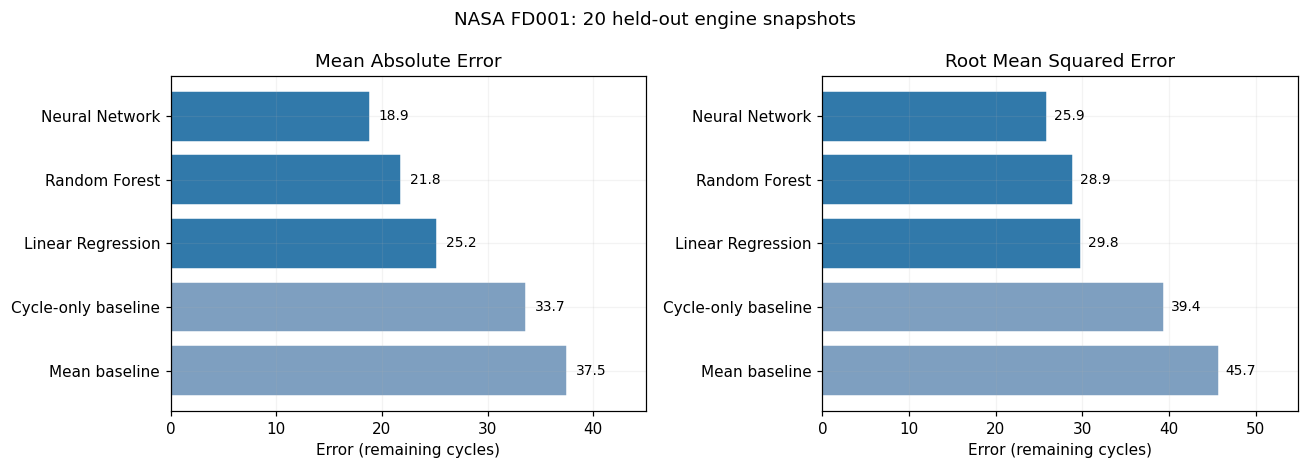

In [6]:
fig, axs=plt.subplots(1,2, figsize=(12.0,4.3))
plot_metrics=metrics.sort_values('RMSE_cycles',ascending=False)
colors=['#7E9FC0' if 'baseline' in m.lower() else '#3179AA' for m in plot_metrics.model]
for ax, metric, ttl in [(axs[0],'MAE_cycles','Mean Absolute Error'),(axs[1],'RMSE_cycles','Root Mean Squared Error')]:
    vals=plot_metrics[metric].to_numpy()
    ax.barh(plot_metrics.model,vals,color=colors,edgecolor='white')
    ax.set(xlabel='Error (remaining cycles)', title=ttl)
    for y,x in enumerate(vals): ax.text(x+.8,y,f'{x:.1f}',va='center',fontsize=9)
    ax.set_xlim(0,max(vals)*1.20)
fig.suptitle('NASA FD001: 20 held-out engine snapshots')
fig.tight_layout()
fig.savefig(FIG/'01_validation_MAE_RMSE_comparison.png',dpi=180,bbox_inches='tight')
plt.show()

## 7. Predicted vs actual remaining useful life

An ideal model lies on the 45° reference line. Scatter reveals systematic underprediction, overprediction, or unusual errors.

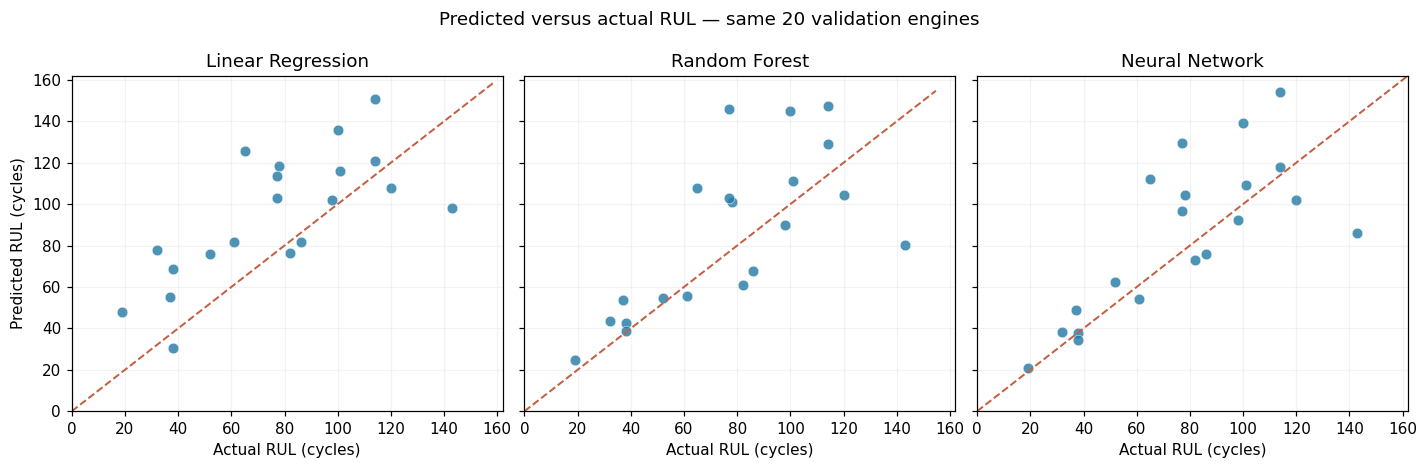

In [7]:
selected=['Linear Regression','Random Forest','Neural Network']
fig,axs=plt.subplots(1,3,figsize=(13,4.3),sharex=True,sharey=True)
for ax,name in zip(axs,selected):
    pred=predictions[f'pred_{name.replace(" ", "_")}'].to_numpy()
    ax.scatter(y_val,pred,alpha=.83,color='#277DA8',edgecolor='white',linewidth=.35,s=48)
    lim=max(y_val.max(),max(pred)) *1.05
    ax.plot([0,lim],[0,lim],'--',color='#C65E42',linewidth=1.3,label='Ideal')
    ax.set(xlim=(0,lim),ylim=(0,lim),title=name, xlabel='Actual RUL (cycles)')
axs[0].set_ylabel('Predicted RUL (cycles)')
fig.suptitle('Predicted versus actual RUL — same 20 validation engines')
fig.tight_layout()
fig.savefig(FIG/'02_validation_actual_vs_predicted.png',dpi=180,bbox_inches='tight')
plt.show()

## 8. Residual errors

Residual = predicted RUL − actual RUL. **Positive** residuals mean the model overestimates life remaining, which may be more consequential for maintenance planning. Observe that all data are simulated and untested in actual flight operations.

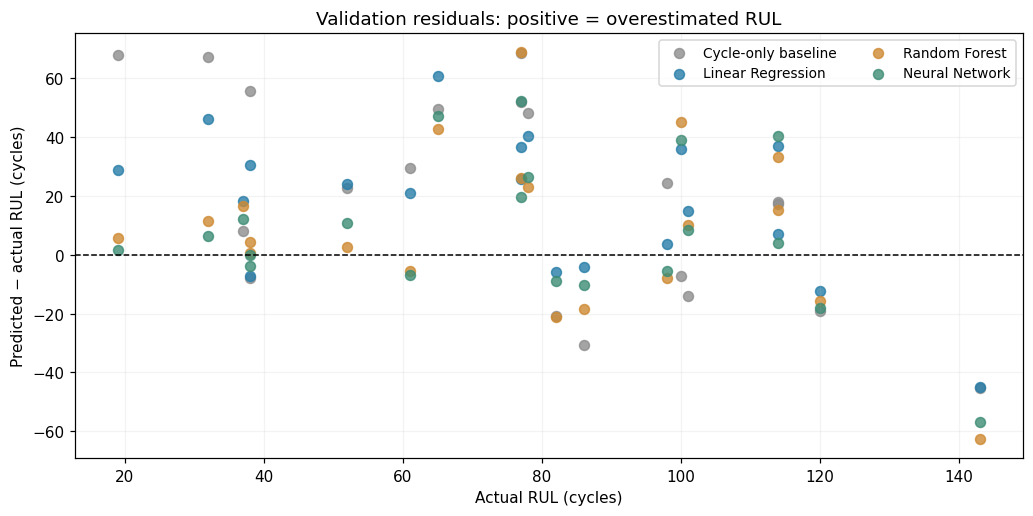

In [8]:
fig,ax=plt.subplots(figsize=(9.5,4.8))
for name,colour in [('Cycle-only baseline','#8D8D8D'),('Linear Regression','#277DA8'),('Random Forest','#CE8A32'),('Neural Network','#3D8C75')]:
    residual = predictions[f'pred_{name.replace(" ", "_")}'].to_numpy()-y_val
    ax.scatter(y_val,residual,label=name,alpha=.80,s=42,color=colour)
ax.axhline(0,color='black',linewidth=1,linestyle='--')
ax.set(xlabel='Actual RUL (cycles)',ylabel='Predicted − actual RUL (cycles)',
       title='Validation residuals: positive = overestimated RUL')
ax.legend(ncol=2,fontsize=9)
fig.tight_layout()
fig.savefig(FIG/'03_validation_residuals.png',dpi=180,bbox_inches='tight')
plt.show()

## 9. Indicative Random Forest feature importance

An impurity-based importance score is useful for exploratory interpretation but can favour predictors with many split opportunities and correlated features. It is **not evidence of physical causation**.

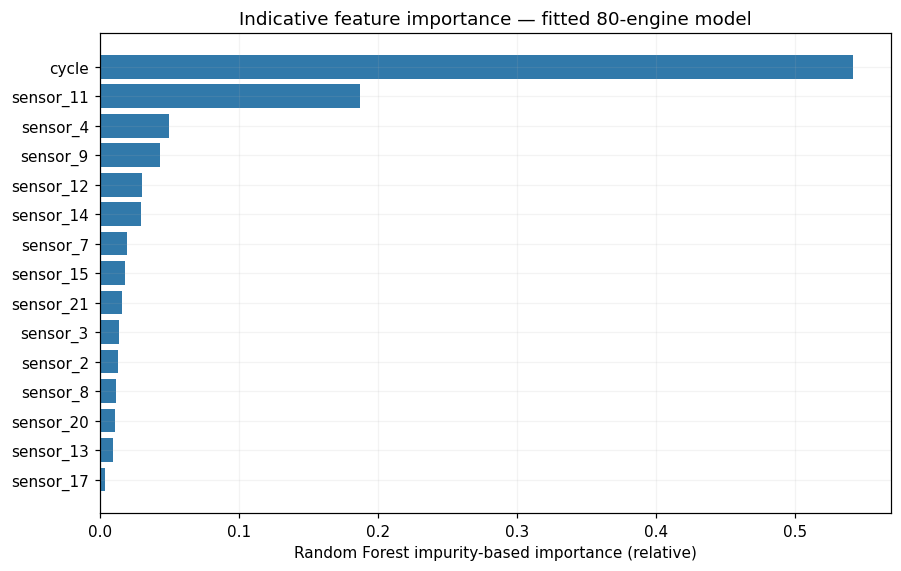

Most important Random Forest features (indicative only):
cycle        0.5419
sensor_11    0.1871
sensor_4     0.0496
sensor_9     0.0432
sensor_12    0.0303
sensor_14    0.0300
sensor_7     0.0199
sensor_15    0.0183


In [9]:
rf = models['Random Forest']
importance = pd.Series(rf.feature_importances_,index=FEATURES).sort_values(ascending=True)
fig,ax=plt.subplots(figsize=(8.3,5.3))
ax.barh(importance.index,importance.values,color='#3179AA')
ax.set(xlabel='Random Forest impurity-based importance (relative)',
       title='Indicative feature importance — fitted 80-engine model')
fig.tight_layout()
fig.savefig(FIG/'04_random_forest_feature_importance.png',dpi=180,bbox_inches='tight')
plt.show()
print('Most important Random Forest features (indicative only):')
print(importance.sort_values(ascending=False).head(8).round(4).to_string())

## 10. One example engine trajectory (diagnostic only)

This plot predicts across the **full history of one held-out engine** to see how model outputs evolve over its life. It is not used to rank models because our primary evaluation uses exactly one selected snapshot per engine.

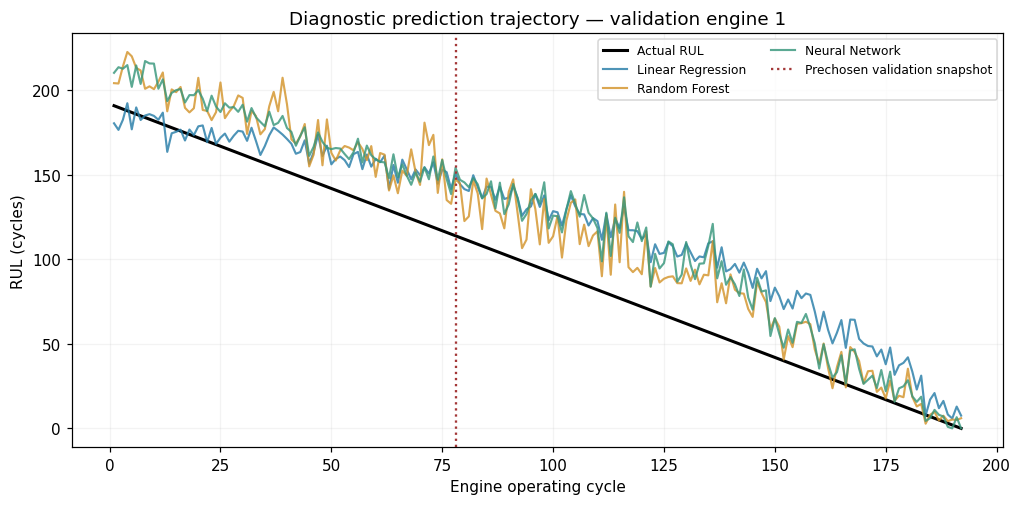

In [10]:
# Optional diagnostic: model predictions along the full history of ONE held-out engine.
# This is for visualization, NOT for selecting or comparing models.
example_engine=int(val.iloc[0].engine_id)
example=val_histories[val_histories.engine_id==example_engine].sort_values('cycle')
fig,ax=plt.subplots(figsize=(9.4,4.7))
ax.plot(example.cycle, example.RUL, color='black',linewidth=2,label='Actual RUL')
for name,color in [('Linear Regression','#277DA8'),('Random Forest','#D3942B'),('Neural Network','#37967B')]:
    p=predict_rul(models[name],example[PREDICTOR_SETS[name]])
    ax.plot(example.cycle,p,label=name,alpha=.82,linewidth=1.4,color=color)
ax.axvline(int(val.iloc[0].cycle),ls=':',color='#A33737',label='Prechosen validation snapshot')
ax.set(xlabel='Engine operating cycle',ylabel='RUL (cycles)',
       title=f'Diagnostic prediction trajectory — validation engine {example_engine}')
ax.legend(fontsize=8,ncol=2)
fig.tight_layout()
fig.savefig(FIG/'05_one_validation_engine_trajectory_DIAGNOSTIC.png',dpi=180,bbox_inches='tight')
plt.show()

## 11. Stage 3 decision and next step

The lowest **validation RMSE** identifies the provisional best approach. The ranking is uncertain because only 20 engine snapshots are evaluated. Stage 4 should refit the chosen configuration(s) on **all 100 original training engines**, including a newly fitted scaler, and then score the 100 official NASA test endpoints **once** using their supplied RUL labels.

**Do not use official test labels to retune the models.**

In [11]:
# Stage 3 model choice is provisional: only 20 snapshots are evaluated.
# No NASA official test data or RUL labels are used here.
primary_winner = str(metrics.iloc[0]['model'])
choice = {
 'dataset':'NASA C-MAPSS FD001',
 'development_training_engines':80,
 'validation_engines':20,
 'validation_scoring':'one artificially censored endpoint per validation engine',
 'ranking_metric':'lowest validation RMSE (cycles)',
 'provisional_winner':primary_winner,
 'all_predictions_clipped_below_zero':True,
 'features':FEATURES,
 'model_parameters':{
     'cycle_only_baseline':'ordinary least squares fit to cycle only',
     'linear_regression':'StandardScaler + ordinary least squares',
     'random_forest':'160 trees, max_depth=14, min_samples_leaf=5, max_features=0.8, random_state=42',
     'neural_network':'StandardScaler + MLP (48,24), ReLU, Adam, alpha=0.01, max_iter=500, early_stopping=True, random_state=42'},
 'important_limitations':['20 validation snapshots; uncertain model rankings',
       'FD001 is simulated and represents one operational condition and one fault mode',
       'same static features at each cycle; no explicit time-series memory',
       'MLP internal early stopping uses rows from development engines, not a separate group-held-out set',
       'validation censoring is synthetic, not identical to official test censoring'],
 'official_test_labels_read':False,
 'next_stage':'Stage 4: refit selected configurations on all 100 original training engines, then score 100 official NASA test endpoints once.'}
(RESULTS/'stage3_model_decision.json').write_text(json.dumps(choice,indent=2))
print('Provisional lowest-RMSE model:',primary_winner)
print('PASS: all project Stage 3 integrity checks. No official NASA test data/labels used.')

Provisional lowest-RMSE model: Neural Network
PASS: all project Stage 3 integrity checks. No official NASA test data/labels used.
